# Lab 02-01 · Complex Numbers, Euler's Formula and Phasors

Companion to chapter [02-01](../../chapters/02-01-complex-numbers-euler-and-phasors.md). Handout: [README.md](README.md).

**How to use this notebook.** Run it top to bottom once (*Run → Run All Cells*). Then go back to each **🔮 Predict** exercise. Write your prediction down *before* changing the parameter and re-running the cell. The `assert` lines check that the simulation agrees with the theory; if you change a parameter and an assert fails, that's expected. Read the message and see why.

In [1]:
import cmath, math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# shared plotting style for the repository (white background, colorblind-safe colors)
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style
    use_style()
except ImportError:
    pass

def polar(mag, angle_deg):
    "Complex number from magnitude and angle in degrees."
    return cmath.rect(mag, math.radians(angle_deg))

def show(name, z):
    "Print a complex number in rectangular and polar form."
    print(f"{name:>10} = {z.real:+.4f} {z.imag:+.4f}j   =  {abs(z):.4f} ∠ {math.degrees(cmath.phase(z)):+.2f}°")

## Part A — Complex arithmetic in Python

Python writes the imaginary unit as `j` attached to a number: `3+4j`. NumPy and the `cmath` module handle complex numbers natively. `abs(z)` is the magnitude, and `cmath.phase(z)` or `np.angle(z)` is the angle **in radians**, computed with the quadrant-correct `atan2`.

In [2]:
z1, z2 = 3 + 4j, 1 - 2j
for name, z in [("z1", z1), ("z2", z2), ("z1+z2", z1 + z2), ("z1*z2", z1 * z2), ("z1/z2", z1 / z2)]:
    show(name, z)

q = z1 / z2
naive = math.degrees(math.atan(q.imag / q.real))      # the quadrant trap
correct = math.degrees(math.atan2(q.imag, q.real))    # what cmath.phase does
print(f"\nangle of z1/z2: naive arctan(y/x) = {naive:.2f}°, atan2(y, x) = {correct:.2f}°")
assert abs(correct - 116.57) < 0.01

        z1 = +3.0000 +4.0000j   =  5.0000 ∠ +53.13°
        z2 = +1.0000 -2.0000j   =  2.2361 ∠ -63.43°
     z1+z2 = +4.0000 +2.0000j   =  4.4721 ∠ +26.57°
     z1*z2 = +11.0000 -2.0000j   =  11.1803 ∠ -10.30°
     z1/z2 = -1.0000 +2.0000j   =  2.2361 ∠ +116.57°

angle of z1/z2: naive arctan(y/x) = -63.43°, atan2(y, x) = 116.57°


**🔮 Predict.** Before running the next cell, write down the angle (principal value, degrees) of each of: $-1 - j$, $-5$, $-j3$, $2 - j2$. Then run it.

In [3]:
for label, z in [("-1 - j", -1 - 1j), ("-5", -5 + 0j), ("-j3", -3j), ("2 - j2", 2 - 2j)]:
    show(label, z)

    -1 - j = -1.0000 -1.0000j   =  1.4142 ∠ -135.00°
        -5 = -5.0000 +0.0000j   =  5.0000 ∠ +180.00°
       -j3 = -0.0000 -3.0000j   =  3.0000 ∠ -90.00°
    2 - j2 = +2.0000 -2.0000j   =  2.8284 ∠ -45.00°


## Part B — Euler's formula by brute force

Sum the Taylor series $e^{j\theta} = \sum_{n=0}^{N} \frac{(j\theta)^n}{n!}$ term by term and watch the partial sums approach $\cos\theta + j\sin\theta$. Each new term is the previous one multiplied by $j\theta/n$: rotated 90° and scaled by $\theta/n$.

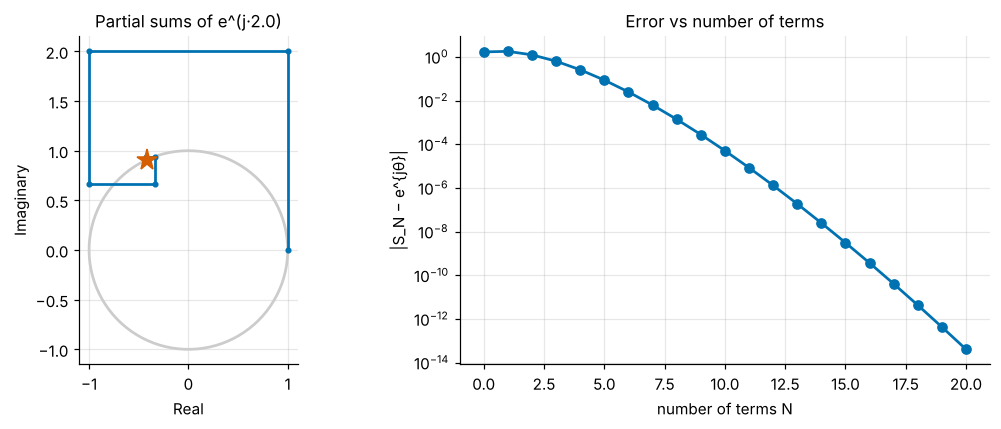

In [4]:
def partial_sums(theta, n_max):
    s, term, out = 0j, 1 + 0j, []
    for n in range(n_max + 1):
        if n > 0:
            term *= 1j * theta / n
        s += term
        out.append(s)
    return np.array(out)

theta = 2.0
S = partial_sums(theta, 20)
target = complex(math.cos(theta), math.sin(theta))
err = np.abs(S - target)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
t = np.linspace(0, 2 * np.pi, 200)
ax1.plot(np.cos(t), np.sin(t), color="0.8")
ax1.plot(S.real, S.imag, "-o", ms=3)
ax1.plot(target.real, target.imag, "*", ms=14)
ax1.set_aspect("equal"); ax1.set_title(f"Partial sums of e^(j·{theta})")
ax1.set_xlabel("Real"); ax1.set_ylabel("Imaginary")
ax2.semilogy(range(len(err)), err + 1e-17, "o-")
ax2.set_xlabel("number of terms N"); ax2.set_ylabel("|S_N − e^{jθ}|"); ax2.set_title("Error vs number of terms")
plt.tight_layout(); plt.show()

assert err[-1] < 1e-12, "20 terms should give machine-precision accuracy at θ = 2"

**🔮 Predict.** How many terms $N$ are needed for the error to drop below $10^{-6}$ at $\theta = \pi$? (Hint: the error is roughly the size of the first omitted term, $\pi^{N+1}/(N+1)!$.) Write a number down, then run the next cell.

In [5]:
theta = math.pi
S = partial_sums(theta, 40)
err = np.abs(S - cmath.exp(1j * theta))
N_needed = int(np.argmax(err < 1e-6))
print(f"At θ = π, the error first drops below 1e-6 at N = {N_needed} (sum = {S[N_needed]:.8f}; exact = -1)")

At θ = π, the error first drops below 1e-6 at N = 16 (sum = -0.99999986-0.00000077j; exact = -1)


## Part C — Adding sinusoids with phasors (Example 02-01.3)

Add $v_1 = 10\cos(\omega t + 30^\circ)$ and $v_2 = 5\sin(\omega t - 20^\circ)$ two ways: point by point in time, and by adding phasors.

        V1 = +8.6603 +5.0000j   =  10.0000 ∠ +30.00°
        V2 = -1.7101 -4.6985j   =  5.0000 ∠ -110.00°
     V1+V2 = +6.9502 +0.3015j   =  6.9567 ∠ +2.48°


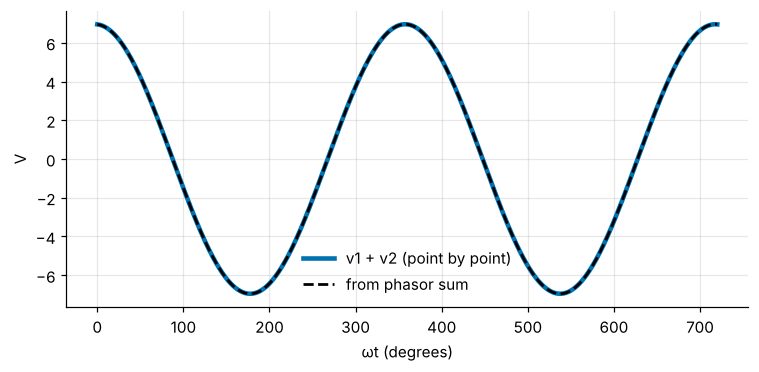

In [6]:
A1, ph1 = 10.0, 30.0       # v1 = A1 cos(wt + ph1)
A2, ph2 = 5.0, -20.0       # v2 = A2 sin(wt + ph2)  -> cosine phase ph2 - 90

V1 = polar(A1, ph1)
V2 = polar(A2, ph2 - 90)
V = V1 + V2
show("V1", V1); show("V2", V2); show("V1+V2", V)

wt = np.linspace(0, 4 * np.pi, 1000)
direct = A1 * np.cos(wt + math.radians(ph1)) + A2 * np.sin(wt + math.radians(ph2))
from_phasor = abs(V) * np.cos(wt + cmath.phase(V))
plt.figure(figsize=(8, 3.5))
plt.plot(np.degrees(wt), direct, lw=3, label="v1 + v2 (point by point)")
plt.plot(np.degrees(wt), from_phasor, "k--", label="from phasor sum")
plt.xlabel("ωt (degrees)"); plt.ylabel("V"); plt.legend(); plt.show()

assert np.max(np.abs(direct - from_phasor)) < 1e-9

**🔮 Predict.** Change `ph2` so that $v_2$ *exactly opposes* $v_1$. What value of `ph2` does that, and what is the resulting amplitude? Then make them *exactly aligned* and predict the amplitude again. (Remember $v_2$ is written as a sine.)

## Part D — Transient versus steady state in an RC low-pass (Example 02-01.4)

The capacitor voltage obeys $RC\,\dot y + y = V_m\cos(\omega t)$. We solve this ODE **numerically from rest**, with no phasors, and compare it with the phasor prediction $y_{ss} = \lvert H\rvert V_m\cos(\omega t + \angle H)$, where $H = 1/(1 + j\omega RC)$. We then measure the simulated output's amplitude and phase over its last two cycles with a least-squares fit.

ωτ = 0.6283
phasor prediction : amplitude 4.2337 V, phase -32.14°
simulation (fit)  : amplitude 4.2337 V, phase -32.14°


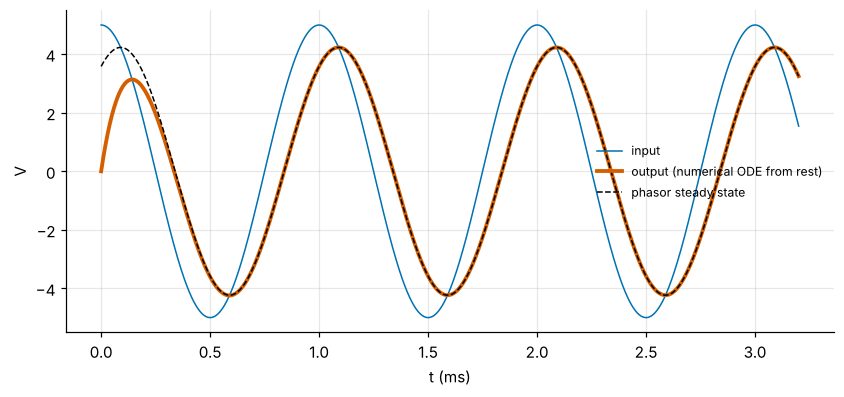

In [7]:
R, Cap, f, Vm = 1e3, 100e-9, 1e3, 5.0     # ohms, farads, hertz, volts   <-- change Cap here
w, tau = 2 * math.pi * f, R * Cap
H = 1 / (1 + 1j * w * tau)
t_end = max(3e-3, 12 * tau + 2 / f)        # long enough for the transient to die out

sol = solve_ivp(lambda t, y: (Vm * np.cos(w * t) - y) / tau, (0, t_end), [0.0],
                max_step=min(tau, 1 / f) / 50, rtol=1e-9, atol=1e-12, dense_output=True)
t = np.linspace(0, t_end, 4000)
y = sol.sol(t)[0]

# least-squares fit of the last two cycles to a cos(wt) + b sin(wt)
tl = np.linspace(t_end - 2 / f, t_end, 2000)
M = np.column_stack([np.cos(w * tl), np.sin(w * tl)])
a, b = np.linalg.lstsq(M, sol.sol(tl)[0], rcond=None)[0]
amp_sim, ph_sim = math.hypot(a, b), math.degrees(math.atan2(-b, a))
print(f"ωτ = {w * tau:.4f}")
print(f"phasor prediction : amplitude {Vm * abs(H):.4f} V, phase {math.degrees(cmath.phase(H)):+.2f}°")
print(f"simulation (fit)  : amplitude {amp_sim:.4f} V, phase {ph_sim:+.2f}°")

plt.figure(figsize=(9, 3.8))
plt.plot(t * 1e3, Vm * np.cos(w * t), lw=1, label="input")
plt.plot(t * 1e3, y, lw=2.5, label="output (numerical ODE from rest)")
plt.plot(t * 1e3, Vm * abs(H) * np.cos(w * t + cmath.phase(H)), "k--", lw=1, label="phasor steady state")
plt.xlabel("t (ms)"); plt.ylabel("V"); plt.legend(fontsize=8); plt.show()

assert abs(amp_sim - Vm * abs(H)) < 1e-4 and abs(ph_sim - math.degrees(cmath.phase(H))) < 0.01

**🔮 Predict.**

1. Change `Cap` to `1e-6` (1 µF). Before running, compute $\omega RC$, $\lvert H\rvert$, the output amplitude and the phase. Then run and compare.
2. With `Cap = 1e-6`, how long (in ms) does the start-up transient last before the output looks like a steady sinusoid? Use "about 5τ".
3. Set `Cap` back to `100e-9` and change `f` to `1/(2*math.pi*tau)` (the corner frequency). What amplitude ratio and phase do you expect?

## Part E — Resonance in a series RLC circuit (Example 02-01.5)

The current phasor is $\mathbf{I} = \mathbf{V}_s / Z(\omega)$ with $Z = R + j\big(\omega L - \tfrac{1}{\omega C}\big)$. Sweep $\omega$ and plot the current amplitude and phase.

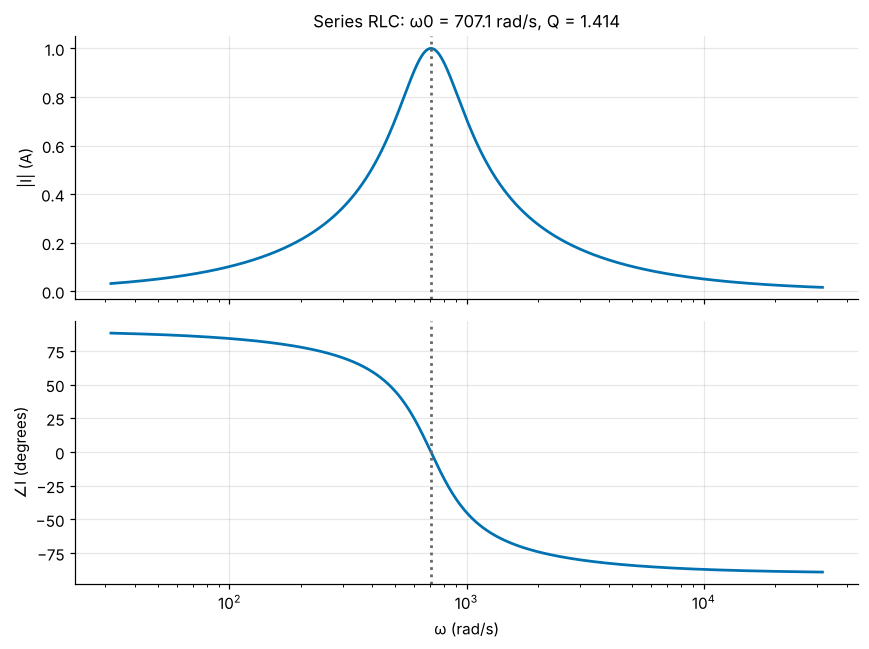

   I(1000) = +0.5000 -0.5000j   =  0.7071 ∠ -45.00°
peak |I| = 1.0000 A at ω ≈ 706.6 rad/s


In [8]:
Rr, L, Cc, Vs = 10.0, 20e-3, 100e-6, 10.0     # <-- change Rr here
wv = np.logspace(1.5, 4.5, 2000)
Z = Rr + 1j * (wv * L - 1 / (wv * Cc))
I = Vs / Z
w0 = 1 / math.sqrt(L * Cc)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax1.semilogx(wv, np.abs(I)); ax1.axvline(w0, ls=":", color="0.4")
ax1.set_ylabel("|I| (A)"); ax1.set_title(f"Series RLC: ω0 = {w0:.1f} rad/s, Q = {w0 * L / Rr:.3f}")
ax2.semilogx(wv, np.degrees(np.angle(I))); ax2.axvline(w0, ls=":", color="0.4")
ax2.set_ylabel("∠I (degrees)"); ax2.set_xlabel("ω (rad/s)")
plt.tight_layout(); plt.show()

I_1000 = Vs / (Rr + 1j * (1000 * L - 1 / (1000 * Cc)))
show("I(1000)", I_1000)
print(f"peak |I| = {np.max(np.abs(I)):.4f} A at ω ≈ {wv[np.argmax(np.abs(I))]:.1f} rad/s")
assert abs(wv[np.argmax(np.abs(I))] - w0) / w0 < 0.01

**🔮 Predict.** Change `Rr` from 10 Ω to 2 Ω. Predict the new peak current, the new $Q = \omega_0L/R$, and whether the peak gets sharper or broader. Does $\omega_0$ change? Run and check.

---

**Done?** Answer the discussion questions in the [lab handout](README.md), then work the [problem set](../../problems/02-01-problems.md).